# 04 · Entrenamiento, evaluación y seguimiento con MLflow

> **Qué haces tú:** ejecutar el cuaderno entero y leer lo que sale. No hay código que escribir. Tarda alrededor de un minuto.

## Objetivo
Entrenar **tres modelos**, compararlos con honestidad, quedarnos con el mejor y **dejarlo guardado y registrado**:

| Modelo | Qué hace | Para qué sirve |
|---|---|---|
| `referencia_sin_aprender` | Da a todos los lotes la misma probabilidad (la tasa base de train) | El **mínimo que hay que superar** (AUC 0,5) |
| `regresion_logistica` | Suma ponderada de variables → probabilidad | Un modelo sencillo y fácil de explicar |
| `gradient_boosting` | Muchos árboles pequeños en secuencia; cada uno corrige los errores de los anteriores | Un modelo más flexible |

Los tres llevan **el mismo preprocesado dentro** (rellenar nulos, estandarizar números, convertir texto a columnas): lo que se entrena es **un único objeto** que, al
servirse en la API, hace exactamente lo mismo.

**Cómo se elige:** cada modelo se entrena con `train`, se compara con `valid` y el mejor se mide en `test`, que **no se usa para elegir**. Además se mide en una
**ventana común** (el año 2016), que sirve para comparar entre versiones de los datos aunque el reparto deslice.

### Preparación
Se carga el paquete y se silencian los avisos de MLflow (solo informan de cómo guarda el modelo) para que la salida sea clara.

In [1]:
import logging
import os

os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'false'
import mlflow  # noqa: E402  (se importa aquí para poder silenciar su registro de mensajes)

for nombre in ('mlflow', 'alembic', 'sqlalchemy'):
    logging.getLogger(nombre).setLevel(logging.ERROR)

import sys
import warnings
from pathlib import Path

import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160, 'display.max_columns', 30, 'display.max_colwidth', 70)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml». Así el cuaderno funciona se abra desde donde se abra.
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from cafe_mlops import config, db   # el paquete del proyecto: lo mismo que ejecutan las órdenes de la terminal

print('Proyecto listo.')
print('Base operacional:', config.DB_OPERACIONAL.name, '· base analítica:', config.DB.name)

con = db.conectar()
if not db.escalar(con, "SELECT COUNT(*) FROM sqlite_master WHERE type = 'table' AND name = 'ml_dataset'"):
    raise FileNotFoundError('Falta ml_dataset: ejecuta antes el cuaderno 03.')

con.close()

import json

from cafe_mlops import mlflow_ui, pipeline_train
from cafe_mlops.modeling import comparar, predict

Proyecto listo.
Base operacional: cqi.db · base analítica: cafe.db


## 1. Entrenar
`pipeline_train.ejecutar()` entrena los tres modelos, los mide en `train`, `valid`, `test` y en la ventana común, elige el mejor **con `valid`**, lo guarda
(`models/`) y lo registra en MLflow. Si los datos y el código no han cambiado desde la última vez, **no vuelve a entrenar** (`sin cambios`): así no se acumulan versiones repetidas.

Lee la salida: primero los datos (cuántos lotes y cuántos **sin especialidad** hay en cada partición), después una línea por modelo, y al final un **aviso de ruido**.

In [2]:
resultado_train = pipeline_train.ejecutar()

[pipeline_train] ejecutando (huella de entrada d07e66a45b41)


  Datos: huella c83699881a8880b9, catas hasta 2016 (versión 1 de los datos). Comprobación temporal OK: train 2010-2014 < valid 2015-2015 < test 2016-2016
    train   866 lotes | 152 sin especialidad (17.6 %)
    valid   197 lotes |  12 sin especialidad (6.1 %)
    test    127 lotes |   5 sin especialidad (3.9 %)


  referencia_sin_aprender  AUC valid 0.500 [0.50; 0.50] | test 0.500 [0.50; 0.50] | AP(<80) test 0.039 (azar 0.039) | ventana común 2016-2016 AUC 0.500 [0.50; 0.50]


  regresion_logistica      AUC valid 0.572 [0.41; 0.73] | test 0.752 [0.54; 0.91] | AP(<80) test 0.114 (azar 0.039) | ventana común 2016-2016 AUC 0.752 [0.54; 0.91]


  gradient_boosting        AUC valid 0.712 [0.55; 0.86] | test 0.852 [0.71; 1.00] | AP(<80) test 0.470 (azar 0.039) | ventana común 2016-2016 AUC 0.852 [0.71; 1.00]


  Evaluación SECUNDARIA (informativa): ventana creciente, varios cortes agrupados


    referencia_sin_aprender  seleccion n=417 sin-especialidad=64 AUC 0.483 [0.42; 0.55] | examen n=324 sin-especialidad=17 AUC 0.552 [0.44; 0.65]
    regresion_logistica      seleccion n=417 sin-especialidad=64 AUC 0.688 [0.62; 0.75] | examen n=324 sin-especialidad=17 AUC 0.617 [0.47; 0.75]
    gradient_boosting        seleccion n=417 sin-especialidad=64 AUC 0.743 [0.68; 0.80] | examen n=324 sin-especialidad=17 AUC 0.736 [0.61; 0.85]
    contraste, gradient_boosting con validación cruzada ALEATORIA sobre las mismas filas (741): AUC 0.767 (optimista: mezcla pasado y futuro)
  AVISO DE RUIDO: valid tiene 12 lotes < 80 y test 5 (la ventana común, 5). Un test único oscila: AUC test 0.852 con IC95 % [0.71; 1.00]. Diferencias de ~0,03 entre modelos no significan nada; no concluyas con una sola cifra (mira también la evaluación agrupada).
  exactitud de test del elegido 0.961 frente a 0.961 de «decir siempre especialidad»: la exactitud no distingue; se usa AUC y precisión media de la clase < 

Successfully registered model 'cafe-especialidad'.
Created version '1' of model 'cafe-especialidad'.


  Mejor modelo: gradient_boosting. Guardado en models/modelo.joblib
  Registrado en MLflow como «cafe-especialidad», versión 1. Para verlo: python -m cafe_mlops.mlflow_ui


## 2. Las métricas, tabla a tabla
Todo lo que acaba de pasar queda en `reports/metricas.json` (sin marcas de tiempo, para que sea reproducible). Lo leemos.

**Cómo leer las métricas:**
- **AUC**: probabilidad de que el modelo ponga más alto a un lote de especialidad que a uno que no. 0,5 = azar; 1 = perfecto.
- **Precisión media de la clase < 80** (`AP`): mide si el modelo pone **arriba los lotes que se quedan sin la nota**, que son los que interesa detectar. Se compara con su **tasa base** (lo que daría el azar).
- **Exactitud**: ¡**no sirve sola**! «Decir siempre especialidad» ya acierta casi siempre, porque los negativos son pocos.

In [3]:
informe = json.loads((config.REPORTES / 'metricas.json').read_text(encoding='utf-8'))
mejor = informe['mejor']

filas = []
for nombre, m in informe['modelos'].items():
    filas.append({'modelo': nombre + ('  ◀ elegido' if nombre == mejor else ''),
                  'AUC valid': m['valid']['auc'], 'AUC test': m['test']['auc'], 'AUC ventana común': m['comun']['auc'],
                  'AP(<80) test': m['test']['ap_no_especialidad'], 'azar AP test': m['test']['tasa_base_no_especialidad']})
pd.DataFrame(filas).set_index('modelo').round(3)

,AUC valid,AUC test,AUC ventana común,AP(<80) test,azar AP test
modelo,,,,,
referencia_sin_aprender,0.500,0.500,0.500,0.039,0.039
regresion_logistica,0.572,0.752,0.752,0.114,0.039
gradient_boosting ◀ elegido,0.712,0.852,0.852,0.470,0.039


### La incertidumbre: los intervalos de confianza
Con tan pocos lotes sin especialidad, una cifra suelta **engaña**. El **intervalo de confianza del 95 %** (calculado por remuestreo) dice entre qué valores
podría estar el AUC real. Si dos modelos tienen intervalos que se solapan mucho, **no puedes decir que uno sea mejor**. Las barras del gráfico son esos intervalos.

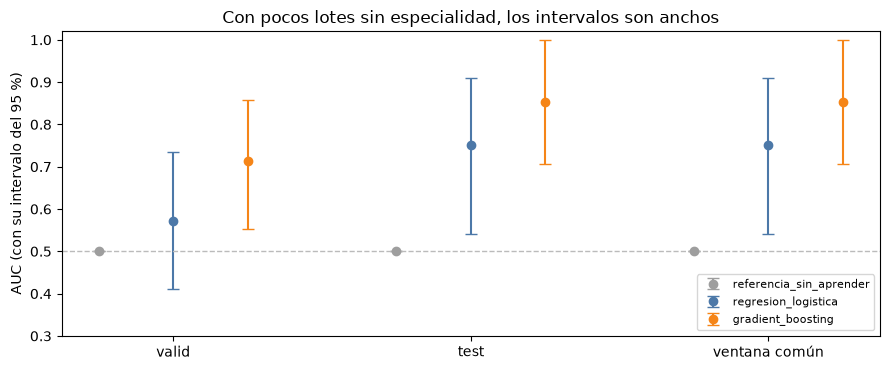

,train,valid,test,ventana común
lotes,866,197,127,127
sin especialidad,152,12,5,5


In [4]:
import matplotlib.pyplot as plt

conjuntos = [('valid', 'valid'), ('test', 'test'), ('comun', 'ventana común')]
colores = {'referencia_sin_aprender': '#9E9E9E', 'regresion_logistica': '#4C78A8', 'gradient_boosting': '#F58518'}
fig, ax = plt.subplots(figsize=(9, 3.8))
ancho = 0.25
for i, (nombre, m) in enumerate(informe['modelos'].items()):
    xs, ys, err = [], [], [[], []]
    for j, (clave, _) in enumerate(conjuntos):
        auc, (lo, hi) = m[clave]['auc'], m[clave]['auc_ic95']
        xs.append(j + (i - 1) * ancho)
        ys.append(auc)
        err[0].append(auc - lo)
        err[1].append(hi - auc)
    ax.errorbar(xs, ys, yerr=err, fmt='o', color=colores[nombre], capsize=4, label=nombre)
ax.axhline(0.5, color='#BBBBBB', linestyle='--', linewidth=1)
ax.set_xticks(range(len(conjuntos)), [etiqueta for _, etiqueta in conjuntos])
ax.set_ylabel('AUC (con su intervalo del 95 %)')
ax.set_ylim(0.3, 1.02)
ax.set_title('Con pocos lotes sin especialidad, los intervalos son anchos')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

tamanos = pd.DataFrame({p: {'lotes': m['n'], 'sin especialidad': m['no_especialidad']}
                        for p, m in {k: informe['modelos'][mejor][k] for k in ('train', 'valid', 'test', 'comun')}.items()})
tamanos.rename(columns={'comun': 'ventana común'})

### Una segunda mirada, solo informativa: varios cortes en el tiempo
Un único test tiene pocos negativos. Como contraste, el proyecto repite la evaluación con **varios cortes** (cada uno entrena con todo lo anterior y prueba en el año siguiente)
y **junta las predicciones** en una sola métrica. No decide nada: la partición principal sigue siendo la temporal de arriba. Y se compara con una **validación cruzada aleatoria**
sobre los mismos lotes, que sale más optimista porque **mezcla pasado y futuro**.

In [5]:
ventana = informe['ventana_creciente_informativa'][mejor]
agrupado = pd.DataFrame([{'grupo': nombre, 'cortes': g['cortes'], 'lotes': g['n'], 'sin especialidad': g['no_especialidad'],
                          'AUC': round(g['auc'], 3), 'IC95 desde': round(g['auc_ic95'][0], 2), 'IC95 hasta': round(g['auc_ic95'][1], 2)}
                         for nombre, g in ventana['grupos'].items()]).set_index('grupo')
display(agrupado)
print(f'Contraste: validación cruzada ALEATORIA sobre las mismas {ventana["cv_aleatoria"]["n"]:,} filas: AUC {ventana["cv_aleatoria"]["auc"]:.3f} (optimista)')

,cortes,lotes,sin especialidad,AUC,IC95 desde,IC95 hasta
grupo,,,,,,
seleccion,2,417,64,0.743,0.68,0.80
examen,2,324,17,0.736,0.61,0.85


Contraste: validación cruzada ALEATORIA sobre las mismas 741 filas: AUC 0.767 (optimista)


## 3. Qué se guardó
`models/metadatos.json` guarda lo necesario para **reproducir y servir** el modelo: variables y tipos, cortes aplicados, lotes por partición, versión de los datos y huella del
dataset (identifica con qué datos se entrenó). La **huella** cambia si cambia un solo dato.

In [6]:
meta = json.loads((config.MODELOS / 'metadatos.json').read_text(encoding='utf-8'))
resumen_meta = {k: meta[k] for k in ('modelo', 'objetivo', 'version_datos', 'anio_cata_maximo', 'particiones', 'filas', 'ventana_comun', 'huella_datos')}
resumen_meta['variables'] = ', '.join(meta['variables'])
pd.Series(resumen_meta, name='valor').to_frame()

,valor
modelo,gradient_boosting
objetivo,el lote alcanza especialidad: Total.Cup.Points >= 80
version_datos,1
anio_cata_maximo,2016
particiones,"{'train': [2009, 2014], 'valid': [2015, 2015], 'test': [2016, 2016]}"
filas,"{'train': 866, 'valid': 197, 'test': 127}"
ventana_comun,"[2016, 2016]"
huella_datos,c83699881a8880b9
variables,"especie, pais, variedad, metodo_proceso, color, altitud_media_m, h..."


### El modelo, usado
`predict.predecir_probabilidad` carga el modelo guardado y devuelve la **probabilidad** de especialidad. Aquí, para cinco lotes de `test` (que el modelo **no vio**),
junto a lo que de verdad pasó en la cata (`y`). Un modelo útil pondría probabilidades **más bajas** en los lotes con `y = 0`.

In [7]:
con = db.conectar()
test = pd.read_sql('SELECT * FROM ml_dataset WHERE particion = ? ORDER BY lote_id', con, params=('test',))
con.close()
muestra = pd.concat([test[test['y'] == 0].head(3), test[test['y'] == 1].head(2)])
muestra = muestra[['lote_id', 'pais', 'variedad', 'metodo_proceso', 'y']].assign(probabilidad=[round(float(p), 3) for p in predict.predecir_probabilidad(muestra)])
muestra.reset_index(drop=True)

,lote_id,pais,variedad,metodo_proceso,y,probabilidad
0,1050,Guatemala,Bourbon,Washed / Wet,0,0.532
1,1076,Nicaragua,None,None,0,0.560
2,1106,Nicaragua,None,None,0,0.815
3,19,China,Catimor,Washed / Wet,1,0.898
4,29,Taiwan,Sumatra,Pulped natural / honey,1,0.926


## 4. El seguimiento con MLflow
**MLflow** es el «cuaderno de laboratorio» de los experimentos: guarda **qué se entrenó, con qué parámetros y qué métricas dio**, y **registra** el modelo con una **versión**
(1, 2, 3...). Cada ejecución del experimento es un entrenamiento; la ejecución `MEJOR-...` guarda el modelo elegido con su **firma** (el nombre y tipo de cada variable de entrada).

Para verlo en el navegador, desde la terminal: `python -m cafe_mlops.mlflow_ui`. Aquí lo resumimos leyendo la propia base de MLflow.

In [8]:
import sqlite3

ejecuciones, versiones = mlflow_ui.resumen()
print(f'Experimento «{config.EXPERIMENTO_MLFLOW}»: {ejecuciones} ejecuciones · versiones registradas de «{config.MODELO_REGISTRADO}»: {versiones}')

m = sqlite3.connect(mlflow_ui.base())
runs = pd.read_sql("""
    SELECT r.name AS ejecucion, l.key AS metrica, l.value AS valor
    FROM runs r JOIN latest_metrics l ON l.run_uuid = r.run_uuid
    WHERE l.key IN ('valid_auc', 'test_auc', 'comun_auc')""", m)
m.close()
runs.pivot_table(index='ejecucion', columns='metrica', values='valor').round(3)

Experimento «cafe-especialidad»: 4 ejecuciones · versiones registradas de «cafe-especialidad»: 1


metrica,comun_auc,test_auc,valid_auc
ejecucion,,,
MEJOR-gradient_boosting,0.852,0.852,0.712
gradient_boosting,0.852,0.852,0.712
referencia_sin_aprender,0.500,0.500,0.500
regresion_logistica,0.752,0.752,0.572


## 5. ¿Es el mismo modelo en todas partes? («comparar»)
Antes de desplegar hay que comprobar dos cosas:

1. **Caminos:** el mismo modelo se puede cargar de varias formas (el paquete, el archivo `joblib`, el formato MLflow, MLflow `pyfunc`, y la API). **Deben dar exactamente la misma
   probabilidad** para los mismos lotes. Si no, algo cambia entre el entrenamiento y el servicio.
2. **Referencia:** el modelo nuevo se compara con la **versión aprobada** (`models/referencia.json`) en la **ventana común**. No se aprueba si **empeora** más que una tolerancia.

In [9]:
filas, n, tolerancia = comparar.comparar_caminos(100)
print(f'{n} lotes reales de test · tolerancia entre caminos: {tolerancia:g}')
pd.DataFrame(filas)

100 lotes reales de test · tolerancia entre caminos: 1e-09


,camino,filas,diferencia_maxima,coincide
0,paquete (referencia),100,0.0,True
1,joblib,100,0.0,True
2,MLflow sklearn,100,0.0,True
3,MLflow pyfunc,100,0.0,True


In [10]:
candidata, referencia = comparar.leer_candidata(), comparar.leer_referencia()
r = comparar.comparar_con_referencia(candidata, referencia)
print(f'Ventana común: {candidata["ventana_comun"][0]}–{candidata["ventana_comun"][1]} (los mismos lotes en todas las versiones)')
pd.Series({'métrica': r['metrica'], 'referencia': round(r['referencia'], 4), 'candidata': round(r['candidata'], 4),
           'diferencia': round(r['diferencia'], 4), 'tolerancia': r['tolerancia'], 'mismos datos que la referencia': r['misma_huella_datos'],
           'resultado': 'APROBADA' if r['aprobada'] else 'RECHAZADA'}, name='valor').to_frame()

Ventana común: 2016–2016 (los mismos lotes en todas las versiones)


,valor
métrica,auc_comun
referencia,0.8525
candidata,0.8525
diferencia,0.0
tolerancia,0.02
mismos datos que la referencia,True
resultado,APROBADA


Con la versión 1 de los datos el modelo candidato **es** la referencia (mismos datos), así que la diferencia es 0. Cuando lleguen datos nuevos (`--hasta 2018`) el modelo
se entrenará con otros años y esta comparación decidirá si la versión nueva se aprueba.

## Resumen
- Se entrenan **tres modelos** con el mismo preprocesado dentro; el elegido sale de `valid` y se mide en `test` y en la **ventana común**.
- Con **pocos lotes sin especialidad**, las métricas oscilan: hay que mirar **los intervalos**, no una sola cifra. La exactitud no distingue.
- El modelo queda guardado (`models/`) y **registrado en MLflow** con su firma y una versión.
- Antes de desplegar se comprueba que todos los caminos dan **la misma probabilidad** y que la candidata **no empeora** a la referencia.

**Siguiente:** en la terminal, `python -m cafe_mlops.pipeline` ejecuta estos cuatro pasos de una vez (y `--hasta 2018` simula la llegada de datos nuevos); después se sirve el modelo con la API.

## Para practicar
1. ¿Por qué la exactitud del modelo elegido es casi igual a la de «decir siempre especialidad»?
2. Si los intervalos del AUC de dos modelos se solapan casi por completo, ¿qué conclusión puedes sacar sobre cuál es mejor?